# Lattice Boltzmann Method (LBM) simulation on Qauntum and Classical Computers

## Import libraries

In [1]:
"""
Lattice Boltzmann Method (LBM) simulation

Simulates 2D fluid flow past a square barrier
"""
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
from IPython.display import clear_output

## Setup parameters & constants

In [2]:
N_STEPS = 2
PLOT_EVERY = 2

U0 = 0.15
TAU = 0.51
# Relaxation parameter
OMEGA = 1/TAU
NQ = 9

# lattice weights
W = np.array([4/9, 1/9, 1/9, 1/9, 1/9, 1/36, 1/36, 1/36, 1/36])

# Reversed direction index (bounce-back)
OPPOSITE = np.array([0, 3, 4, 1, 2, 7, 8, 5, 6])

# (9, 2) Integer lattice velocity vectors
C = np.array([[0, 0], [1, 0], [0, 1], [-1, 0], [0, -1], [1, 1], [-1, 1], [-1, -1], [1, -1],])

## Domain Setup & Initialization

In [3]:
# Geometry: square obstacle mask
n = 4
NX, NY = n, n
Xg, Yg = np.meshgrid(np.arange(NX), np.arange(NY), indexing="ij") 
center_idx = list(range(NX // 2 - 1, NX // 2 + 1))
mask = np.zeros((NX, NY), dtype=bool)
mask[np.ix_(center_idx, center_idx)] = True
obstacle = mask

## Quantum circuit parameters

In [4]:
# Qubits: idx(4) | which(1) | row(s) | col(s) | val(1)
n_idx = 4

# qubits per row/col register
s = int(np.log2(n))
IDX = list(range(0, n_idx))
WHICH = n_idx
ROW = list(range(n_idx + 1, n_idx + 1 + s))
COL = list(range(n_idx + 1 + s, n_idx + 1 + 2 * s))
VAL = n_idx + 1 + 2 * s
WIRES = IDX + [WHICH] + ROW + COL + [VAL]
N_WIRES = len(WIRES)

print(f"Total number of qubits: {N_WIRES} = 4 (IDX) + 1 (WHICH) + {s} (ROW) + {s} (COL) + 1 (VAL)")

Total number of qubits: 10 = 4 (IDX) + 1 (WHICH) + 2 (ROW) + 2 (COL) + 1 (VAL)


## LBM Utility Functions

In [5]:
def equilibrium(rho, ux, uy):
    # Equilibrium distribution fucntion
    usqr = ux ** 2 + uy ** 2
    feq = np.empty((NX, NY, NQ))
    for i in range(NQ):
        cu = C[i, 0] * ux + C[i, 1] * uy
        feq[:, :, i] = W[i] * rho * (1 + 3 * cu + 4.5 * cu ** 2 - 1.5 * usqr)
    return feq

def compute_vorticity(ux, uy):
    duy_dx = np.gradient(uy, axis=0)
    dux_dy = np.gradient(ux, axis=1)
    return duy_dx - dux_dy

def plot(step, rho, ux, uy, speed, obstacle):
        clear_output(wait=True)
        print(f"step {step:5d}/{N_STEPS} | max|u| = {speed.max():.5f} | mean rho = {rho.mean():.5f}")
        vort = compute_vorticity(ux, uy)
        vort[obstacle] = 0.0
        plt.figure(figsize=(11, 3.6))
        plt.imshow(vort.T, cmap="RdBu_r", origin="lower", vmin=-0.1, vmax=0.1)
        plt.colorbar(label="vorticity (curl of velocity)")
        plt.title(f"Vorticity field (step {step}/{N_STEPS}, max|u|={speed.max():.4f})")
        plt.xlabel("x (lattice units)")
        plt.ylabel("y (lattice units)")
        plt.imshow(np.ma.masked_where(~obstacle.T, np.zeros((NX, NY))), cmap='gray', alpha=1, origin='lower')
        plt.tight_layout()
        plt.show()

---

# Quantum LBM Circuit

This quantum circuit implements the **collision, bounce-back, and streaming** operations of the **Lattice Boltzmann Method (LBM)** at the level of the particle distribution functions.

The current distribution $f$ and the equilibrium distribution $f^{eq}$ are used as inputs to the quantum circuit. The equilibrium distribution $f^{eq}$ and the required **macroscopic quantities** are calculated **classically**.

## 1. Collision

The collision operation is implemented using a **PREPARE–SELECT–PREPARE†** structure.

The LBM collision equation is

$$
f^*=(1-\Omega)f+\Omega f^{eq}.
$$

To represent the collision coefficients as valid quantum amplitudes, they are normalized using

$$
\Lambda=|1-\Omega|+|\Omega|.
$$

The `WHICH` qubit is prepared using

$$
\phi =
2\arccos
\left(
\sqrt{\frac{|1-\Omega|}{\Lambda}}
\right),
$$

so that

$$
|0\rangle
\rightarrow
\sqrt{\frac{|1-\Omega|}{\Lambda}}|0\rangle
+
\sqrt{\frac{|\Omega|}{\Lambda}}|1\rangle.
$$

The `WHICH` qubit selects between the current distribution $f$ and the equilibrium distribution $f^{eq}$ used in the collision operation.:

- `WHICH = 0`: the current distribution $f$.
- `WHICH = 1`: the equilibrium distribution $f^{eq}$.

The corresponding distribution values are encoded into the `VAL` qubit using controlled $R_Y$ rotations.

For a distribution value $v$, the rotation angle is

$$
\theta =
2\arcsin
\left(
\frac{v}{\mathrm{scale}}
\right),
$$

so that

$$
\sin\left(\frac{\theta}{2}\right) = \frac{v}{\mathrm{scale}}.
$$

Therefore, the amplitude of the $|1\rangle$ state of the `VAL` qubit represents the scaled distribution value.

The sign of each collision coefficient is also encoded in the corresponding controlled $R_Y$ rotation. This is necessary when $\Omega>1$, because

$$
1-\Omega<0.
$$

The `PREPARE†` operation,

```python
qml.RY(-phi, wires=WHICH)
```

completes the **PREPARE–SELECT–PREPARE†** sequence and places the normalized collision combination in the `WHICH = 0` branch.

The corresponding quantum amplitude represents

$$
g=
\frac{1-\Omega}{\Lambda}f
+
\frac{\Omega}{\Lambda}f^{eq}.
$$

The physical collision distribution is recovered from the corresponding matrix element of the quantum unitary by multiplying only by the known LCU normalization:

$$
f^*=\Lambda g.
$$

Therefore,

$$
\boxed{
f^*=(1-\Omega)f+\Omega f^{eq}
}.
$$

The collision operation is thus performed by the quantum circuit, while the extraction step only removes the known LCU normalization.

## 2. Bounce-back

The **center-block replacement** uses the `OPPOSITE` mapping to replace the corresponding distribution with the opposite-direction distribution $f_j$.

For the center region, the operation is independent of the `WHICH` qubit. The value

$$
f_j
$$

is directly encoded into the `VAL` qubit.

This implements the **bounce-back operation**, where the particle distribution is reflected into its opposite lattice direction at the boundary.

## 3. Streaming

The **controlled permutation operators** acting on the `ROW` and `COL` registers implement the streaming operation.

For each lattice direction $i$, the corresponding discrete velocity

$$
C_i=(c_{x,i},c_{y,i})
$$

determines the required shift of the row and column registers.

The controlled permutation operators therefore perform

$$
(r,c)
\rightarrow
(r+c_{x,i},c+c_{y,i}),
$$

with periodic indexing.

This moves each particle distribution to its corresponding neighboring lattice site according to its lattice velocity.

## 4. Quantum Encoding

The distribution-function values are encoded using **angle encoding with quantum addressing**.

The quantum registers have the following roles:

- `IDX`: identifies which lattice direction or distribution $i$ is being processed.
- `WHICH`: selects between the current distribution $f$ and the equilibrium distribution $f^{eq}$ during the collision operation.
- `ROW`: identifies the row of the lattice.
- `COL`: identifies the column of the lattice.
- `VAL`: stores the encoded distribution value through the amplitude generated by an $R_Y$ rotation.

The `IDX`, `ROW`, and `COL` registers therefore act as the **address** of each distribution value, while `WHICH` selects which distribution is being encoded.

For a given address, a controlled $R_Y$ rotation is applied to the `VAL` qubit:

$$
\boxed{
\mathrm{IDX}
+
\mathrm{WHICH}
+
\mathrm{ROW}
+
\mathrm{COL}
\longrightarrow
R_Y(\theta)\text{ on VAL}
}
$$

For a distribution value $v$, the `VAL` qubit undergoes

$$
\cos\left(\frac{\theta}{2}\right)|0\rangle
+
\sin\left(\frac{\theta}{2}\right)|1\rangle,
$$

where

$$
\theta =
2\arcsin
\left(
\frac{v}{\mathrm{scale}}
\right).
$$

Therefore,

$$
\sin\left(\frac{\theta}{2}\right) = \frac{v}{\mathrm{scale}}.
$$

Thus, the numerical value $v$ is represented by the amplitude of the $|1\rangle$ state of the `VAL` qubit.

The encoding is therefore not amplitude encoding of an entire matrix into one quantum state. Instead, the matrix elements are **individually addressed and encoded as amplitudes of the** **`VAL`** **qubit** using controlled $R_Y$ rotations.

During the collision operation, the `WHICH` qubit determines whether the encoded value corresponds to $f$ or $f^{eq}$. The amplitudes of these two branches are combined through the **PREPARE–SELECT–PREPARE†** construction.

The LCU normalization

$$
\Lambda=|1-\Omega|+|\Omega|
$$

is used to make the collision coefficients suitable for quantum-state preparation. The resulting amplitude corresponds to the normalized collision result, and the physical collision value is recovered during extraction by multiplying by $\Lambda$.

## 5. Matrix Extraction

After the complete quantum circuit is constructed, its overall unitary operator $U$ is obtained.

For a circuit containing $N$ qubits,

$$
U\in\mathbb{C}^{2^N\times2^N}.
$$

The final distribution functions are extracted directly from selected matrix elements of $U$.

For each distribution direction $i$ and each initial lattice position $(r_0,c_0)$, where $r_0$ and $c_0$ denote the row and column indices, respectively, the streaming operation determines the final lattice position. Here, $n$ is the number of lattice sites along each spatial dimension, giving an $n\times n$ lattice. The quantities $d_r$ and $d_c$ are the row and column components of the discrete velocity associated with direction $i$, respectively. Thus, $d_r$ specifies the displacement in the row direction, while $d_c$ specifies the displacement in the column direction. The indices satisfy $r_0,c_0\in{0,\ldots,n-1}$, and the final position is

$$
r_f=(r_0+d_r)\bmod n,
$$

$$
c_f=(c_0+d_c)\bmod n.
$$

The extraction selects the state corresponding to the appropriate `IDX`, `WHICH = 0`, initial row and column indices, and `VAL = 0`:

$$
|i,0,r_0,c_0,0\rangle.
$$

After the quantum operations, the corresponding output state is

$$
|i,0,r_f,c_f,1\rangle.
$$

Therefore, the relevant matrix element of the unitary is

$$
\langle i,0,r_f,c_f,1|
U
|i,0,r_0,c_0,0\rangle.
$$

Its real part is multiplied by `scale` to recover the encoded distribution amplitude:

$$
g=
\operatorname{Re}
\left[
\langle i,0,r_f,c_f,1|
U
|i,0,r_0,c_0,0\rangle
\right]
\times\mathrm{scale}.
$$

For collision points, this amplitude represents the **normalized LCU collision result**:

$$
g=
\frac{1-\Omega}{\Lambda}f
+
\frac{\Omega}{\Lambda}f^{eq}.
$$

Therefore, the physical collision distribution is recovered by multiplying the extracted amplitude by $\Lambda$:

$$
f^*=\Lambda g.
$$

Thus, the extraction step does **not** recalculate the collision using $f$ and $f^{eq}$. It only reads the appropriate matrix element of the quantum unitary and removes the known LCU normalization.

For bounce-back points, the corresponding distribution is directly encoded using the opposite-direction distribution $f_j$. Since this operation is not part of the LCU collision combination, its extracted value does not require multiplication by $\Lambda$.

Finally, the extracted values are placed at the streamed positions $(r_f,c_f)$, reconstructing the final distribution matrix

$$
f^{\mathrm{next}}.
$$

## Overall

Therefore, the quantum circuit implements the main distribution-function transformations of the Lattice Boltzmann Method:

$$
\boxed{
\text{Collision}
\;\rightarrow\;
\text{Bounce-back}
\;\rightarrow\;
\text{Streaming}
}
$$

More specifically, the quantum circuit performs

$$
\boxed{
f
\overset{\text{Collision}}{\longrightarrow}
f^*
\overset{\text{Bounce-back}}{\longrightarrow}
f^{\mathrm{BB}}
\overset{\text{Streaming}}{\longrightarrow}
f^{\mathrm{next}}
}
$$

at the level of the particle distribution functions.

The **collision**, **bounce-back**, and **streaming** transformations are implemented through quantum operations acting on the distribution values and lattice-position registers.

However, the equilibrium distribution $f^{eq}$ and the required **macroscopic quantities**, such as density and velocity, are calculated **classically**.

The calculated $f^{eq}$ values are then encoded into the quantum circuit and used in the collision operation.

Finally, selected matrix elements of the overall quantum unitary are extracted to reconstruct the final classical distribution functions.



## 6. Real Quantum Hardware: Measurement-Based Distribution Extraction

The matrix-element extraction described above uses the explicit unitary matrix $U$, which is convenient for classical simulation but is not directly available on a real quantum computer.

On quantum hardware, the circuit is executed repeatedly and the required information is obtained from measurements of the qubit registers.

For each lattice direction $i$ and initial lattice position $(r_0,c_0)$, the circuit is initialized in

$$
|i,0,r_0,c_0,0\rangle.
$$

After applying the complete quantum circuit, the target output state is

$$
|i,0,r_f,c_f,1\rangle,
$$

where

$$
r_f=(r_0+d_r)\bmod n,
\qquad
c_f=(c_0+d_c)\bmod n.
$$

The corresponding transition amplitude is

$$
A_{i,r_0,c_0}
=
\langle i,0,r_f,c_f,1|
U
|i,0,r_0,c_0,0\rangle.
$$

A direct computational-basis measurement provides the probability

$$
P_{i,r_0,c_0}
=
|A_{i,r_0,c_0}|^2,
$$


the encoded distribution value is then reconstructed as

$$
g=
A_{i,r_0,c_0}\times\mathrm{scale}.
$$

For an ordinary collision point, the quantum circuit produces the normalized LCU collision result

$$
g=
\frac{1-\Omega}{\Lambda}f_i
+
\frac{\Omega}{\Lambda}f_i^{eq},
$$

and the physical post-collision distribution is recovered as

$$
f_i^*=\Lambda g.
$$

For a bounce-back point, the circuit directly encodes the opposite-direction distribution

$$
f_j,
\qquad
j=\operatorname{OPPOSITE}(i),
$$

so the physical bounced-back distribution is recovered without the LCU normalization:

$$
f_i^{BB}=g.
$$

This procedure is repeated for all lattice directions and lattice positions. The reconstructed values are then assembled into the final distribution matrix

$$
f^{\mathrm{next}}\in\mathbb{R}^{n\times n\times9}.
$$

Thus, on a real quantum computer, the complete unitary matrix $U$ does not need to be explicitly constructed or stored. Instead, the required transition amplitudes are estimated experimentally from repeated executions of the quantum circuit, and these measured values are used to reconstruct the final LBM distribution matrix.

## Quantum circuit configurations

In [6]:
def bits(val, width):
    return [int(b) for b in format(val, f'0{width}b')]

def combine(bit_list):
    v = 0
    for b in bit_list:
        v = v * 2 + b
    return v

def perm_unitary(shift, dim):
    P = np.zeros((dim, dim))
    for k in range(dim):
        P[(k + shift) % dim, k] = 1.0
    return P

def safe_angle(v):
    x = np.clip(v / scale, -1.0, 1.0)
    return 2 * np.arcsin(x)


def circuit(f, feq):
    # Distribution-value encoding

    # LCU normalization:
    # Lambda = |1 - OMEGA| + |OMEGA|
    # This allows the collision coefficients to be normalized
    # even when OMEGA > 1.
    LAMBDA = abs(1 - OMEGA) + abs(OMEGA)

    # Normalized probabilities for the f and feq branches
    p_f = abs(1 - OMEGA) / LAMBDA

    # Angle: cos(phi/2)=sqrt(p_f)
    phi = 2 * np.arccos(np.sqrt(p_f))

    for i in range(0, 9):    
        idx_b = bits(i, n_idx)
        j = OPPOSITE[i]

        # Prepare WHICH qubit for collision operation
        qml.RY(phi, wires=WHICH)

        for r in range(n):
            for c in range(n):
                r_b = bits(r, s)
                c_b = bits(c, s)
                is_center = (r in center_idx) and (c in center_idx)

                if is_center:
                    # Overwrite with f_j directly (which-independent)
                    # Bounce-back operation
                    theta = safe_angle(f[r,c,j])
                    ctrl_wires = IDX + ROW + COL
                    ctrl_vals = idx_b + r_b + c_b
                    qml.ctrl(qml.RY(theta, wires=VAL),
                             control=ctrl_wires, control_values=ctrl_vals)

                else:
                    # LCU SELECT of f_i (which=0) and feq_i (which=1)
                    # Collision operation
                    theta = safe_angle(f[r, c, i])
                    theta_eq = safe_angle(feq[r, c, i])

                    # The coefficient of f is (1 - OMEGA).
                    # For OMEGA > 1, this coefficient is negative,
                    # so the f branch requires a sign change.
                    theta *= np.sign(1 - OMEGA)

                    # The coefficient of feq is OMEGA.
                    # Its sign is included for completeness :)
                    theta_eq *= np.sign(OMEGA)

                    ctrl_wires = IDX + [WHICH] + ROW + COL
                    qml.ctrl(qml.RY(theta, wires=VAL),
                             control=ctrl_wires,
                             control_values=idx_b + [0] + r_b + c_b)
                    qml.ctrl(qml.RY(theta_eq, wires=VAL),
                             control=ctrl_wires,
                             control_values=idx_b + [1] + r_b + c_b)

        # Prepare-dagger: completes the LCU construction and produces
        # the normalized weighted combination of f and feq for the collision step
        qml.RY(-phi, wires=WHICH)

    # Streaming step of the LBM
    for i in range(0, 9):
        idx_b = bits(i, n_idx)
        dr, dc = C[i]
        
        if dr:
            P = perm_unitary(dr, n)
            qml.ctrl(qml.QubitUnitary(P, wires=ROW),
                     control=IDX, control_values=idx_b)
        if dc:
            P = perm_unitary(dc, n)
            qml.ctrl(qml.QubitUnitary(P, wires=COL),
                     control=IDX, control_values=idx_b)


def extract(scale):
    # Extract particle distribution from the final unitary operator U (U = U_shift * U_encoding) implemented by the quantum circuit
    mat = np.zeros((n, n, 9))

    for i in range(9):
        idx_b = bits(i, n_idx)
        dr, dc = C[i]

        for r0 in range(n):
            for c0 in range(n):
                rf, cf = (r0 + dr) % n, (c0 + dc) % n

                in0 = combine(idx_b + [0] + bits(r0, s) + bits(c0, s) + [0])
                out0 = combine(idx_b + [0] + bits(rf, s) + bits(cf, s) + [1])
                amp0 = np.real(U[out0, in0]) * scale # Basically, it doesn't need np.real, but I included it just in case :)

                # Recover the physical collision result from the normalized LCU result.
                LAMBDA = abs(1 - OMEGA) + abs(OMEGA)
                is_center = (r0 in center_idx) and (c0 in center_idx)

                if is_center:
                    
                    # Bounce-back is not part of the LCU normalization.
                    mat[rf, cf, i] = amp0
                    
                else:
                    # The quantum circuit produces the normalized LCU combination:
                    # g = [(1 - OMEGA)/LAMBDA] * f + [OMEGA/LAMBDA] * feq
                    # Multiplying by LAMBDA recovers the physical
                    # LBM collision result.
                    mat[rf, cf, i] = LAMBDA * amp0

    return mat

## Quantum simulation test

step     2/2 | max|u| = 0.13198 | mean rho = 1.00000


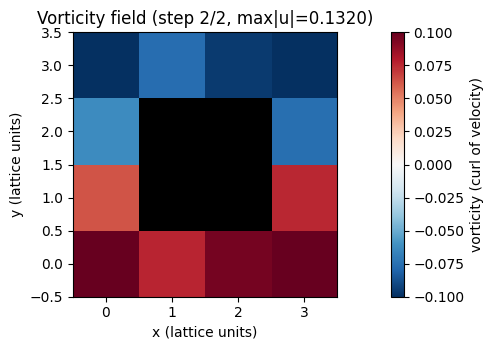

Simulation complete!
Final step 2/2 | max|u| = 0.13198


In [7]:
rho = np.ones((n, n))
ux = np.full((n, n), U0)
uy = np.zeros((n, n))

# Add a small sinusoidal perturbation to the x-velocity to introduce a spatially varying flow.
ux += 0.01 * U0 * np.sin(2 * np.pi * Yg /n)
ux[obstacle] = 0.0
uy[obstacle] = 0.0
f = equilibrium(rho, ux, uy)

for step in range(1, N_STEPS + 1):

    # Equilibrium distribution
    feq = equilibrium(rho, ux, uy)
    scale = max(np.max(np.abs(f)), np.max(np.abs(feq)))
    U = qml.matrix(circuit, wire_order=WIRES)(f, feq)
    
    # Update the particle distribution
    f = extract(scale)

    rho = np.sum(f, axis=2)
    ux = np.sum(f * C[:, 0], axis=2) / rho
    uy = np.sum(f * C[:, 1], axis=2) / rho
    
    if step % PLOT_EVERY == 0 or step == 1:
        speed = np.sqrt(ux ** 2 + uy ** 2)
        plot(step, rho, ux, uy, speed, obstacle)

f_quantum = np.copy(f)
print("Simulation complete!")
print(f"Final step {step}/{N_STEPS} | max|u| = {speed.max():.5f}")

In [8]:
# Quantum circuit architecture
print(qml.draw(circuit, wire_order=WIRES)(f, feq))

0: ───────────╭○─────────╭○────────╭○─────────╭○────────╭○─────────╭○────────╭○──────── ···
1: ───────────├○─────────├○────────├○─────────├○────────├○─────────├○────────├○──────── ···
2: ───────────├○─────────├○────────├○─────────├○────────├○─────────├○────────├○──────── ···
3: ───────────├○─────────├○────────├○─────────├○────────├○─────────├○────────├○──────── ···
4: ──RY(1.92)─├○─────────├●────────├○─────────├●────────├○─────────├●────────├○──────── ···
5: ───────────├○─────────├○────────├○─────────├○────────├○─────────├○────────├○──────── ···
6: ───────────├○─────────├○────────├○─────────├○────────├○─────────├○────────├○──────── ···
7: ───────────├○─────────├○────────├○─────────├○────────├●─────────├●────────├●──────── ···
8: ───────────├○─────────├○────────├●─────────├●────────├○─────────├○────────├●──────── ···
9: ───────────╰RY(-2.45)─╰RY(2.37)─╰RY(-3.14)─╰RY(2.76)─╰RY(-3.14)─╰RY(2.76)─╰RY(-2.45) ···

0: ··· ─╭○────────╭○─────────╭○────────╭○────────╭○────────╭○─────────╭○───────

## Classical simulation test

step     2/2 | max|u| = 0.13198 | mean rho = 1.00000


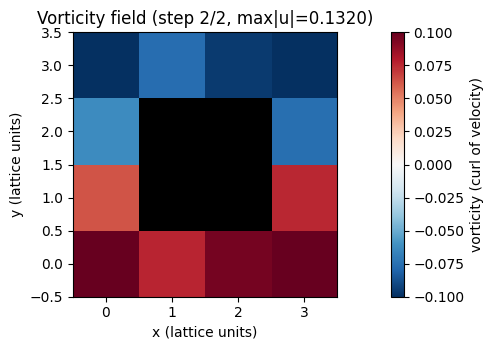

Simulation complete!
Final step 2/2 | max|u| = 0.13198


In [9]:
rho = np.ones((NX, NY))
ux = np.full((NX, NY), U0)
uy = np.zeros((NX, NY))

# Add a small sinusoidal perturbation to the x-velocity to introduce a spatially varying flow.
ux += 0.01 * U0 * np.sin(2 * np.pi * Yg / NY)
ux[obstacle] = 0.0
uy[obstacle] = 0.0
f = equilibrium(rho, ux, uy)

for step in range(1, N_STEPS + 1):

    # Equilibrium distribution
    feq = equilibrium(rho, ux, uy)
    f_post = f - OMEGA * (f - feq)

    for i in range(NQ):
        f_post[obstacle, i] = f[obstacle, OPPOSITE[i]]

    f_new = np.empty_like(f_post)
    for i in range(NQ):
        f_new[:, :, i] = np.roll(np.roll(f_post[:, :, i], C[i, 0], axis=0), C[i, 1], axis=1)

    # Update the particle distribution
    f = f_new

    rho = np.sum(f, axis=2)
    ux = np.sum(f * C[:, 0], axis=2) / rho
    uy = np.sum(f * C[:, 1], axis=2) / rho

    if step % PLOT_EVERY == 0 or step == 1:
        speed = np.sqrt(ux ** 2 + uy ** 2)
        plot(step, rho, ux, uy, speed, obstacle)

f_classic = np.copy(f)
print("Simulation complete!")
print(f"Final step {step}/{N_STEPS} | max|u| = {speed.max():.5f}")

## Comparing the Classical and Quantum Results for $f$

In [10]:
print(f"Mean absolute error: {np.mean(np.abs(f_classic - f_quantum)):.2e}")

Mean absolute error: 1.45e-17


## Full Classical LBM Simulation

step  8000/8000 | max|u| = 0.17374 | mean rho = 1.00000


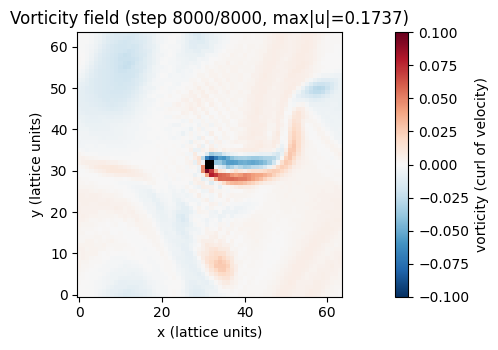

Simulation complete!
Final step 8000/8000 | max|u| = 0.17374


In [11]:
N_STEPS = 8000
PLOT_EVERY = 1000

n = 64
NX, NY = n, n
Xg, Yg = np.meshgrid(np.arange(NX), np.arange(NY), indexing="ij")   
center_idx = list(range(NX // 2 - 1, NX // 2 + 1))  
mask = np.zeros((NX, NY), dtype=bool)
mask[np.ix_(center_idx, center_idx)] = True
obstacle = mask

rho = np.ones((NX, NY))
ux = np.full((NX, NY), U0)
uy = np.zeros((NX, NY))

# Add a small sinusoidal perturbation to the x-velocity to introduce a spatially varying flow.
ux += 0.01 * U0 * np.sin(2 * np.pi * Yg / NY)
ux[obstacle] = 0.0
uy[obstacle] = 0.0
f = equilibrium(rho, ux, uy)

for step in range(1, N_STEPS + 1):

    # Equilibrium distribution
    feq = equilibrium(rho, ux, uy)
    f_post = f - OMEGA * (f - feq)

    for i in range(NQ):
        f_post[obstacle, i] = f[obstacle, OPPOSITE[i]]

    f_new = np.empty_like(f_post)
    for i in range(NQ):
        f_new[:, :, i] = np.roll(np.roll(f_post[:, :, i], C[i, 0], axis=0), C[i, 1], axis=1)

    # Update the particle distribution
    f = f_new

    rho = np.sum(f, axis=2)
    ux = np.sum(f * C[:, 0], axis=2) / rho
    uy = np.sum(f * C[:, 1], axis=2) / rho
    
    if step % PLOT_EVERY == 0 or step == 1:
        speed = np.sqrt(ux ** 2 + uy ** 2)
        plot(step, rho, ux, uy, speed, obstacle)

print("Simulation complete!")
print(f"Final step {step}/{N_STEPS} | max|u| = {speed.max():.5f}")